In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [2]:
data = pd.read_csv(r"C:\Users\apkar\OneDrive\Documents\Projects\AIBD\AIBD-Project\GSE157103_genes.tpm.tsv\GSE157103_genes.tpm.tsv",sep = '\t')


In [3]:
data

,#symbol,C1,C2,C3,C4,C5,C6,C7,C8,C9,...,NC17,NC18,NC19,NC20,NC21,NC22,NC23,NC24,NC25,NC26
0,A1BG,0.49,0.29,0.26,0.45,0.17,0.21,0.49,0.12,0.51,...,0.37,0.33,0.25,0.20,0.40,0.30,0.70,0.75,2.80,0.22
1,A1CF,0.00,0.00,0.00,0.01,0.00,0.00,0.01,0.00,0.01,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
2,A2M,0.21,0.14,0.03,0.09,0.00,0.08,0.23,0.08,0.88,...,0.07,0.06,0.11,0.01,0.04,0.02,0.02,0.27,0.04,0.28
3,A2ML1,0.04,0.00,0.02,0.07,0.05,0.04,0.03,0.01,0.02,...,0.01,0.00,0.00,0.02,0.02,0.02,0.01,0.00,0.00,0.00
4,A3GALT2,0.07,0.00,0.00,0.00,0.07,0.00,0.07,0.00,0.79,...,0.18,0.00,0.04,0.00,0.00,0.00,0.00,0.06,0.00,0.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19467,ZYG11A,0.06,0.14,0.28,0.27,0.07,0.20,0.19,0.03,0.33,...,0.10,0.06,0.06,0.10,0.06,0.24,0.12,0.14,0.33,0.10
19468,ZYG11B,8.17,8.20,3.62,7.88,5.96,7.14,7.94,7.11,7.93,...,8.82,2.65,2.93,4.58,2.82,1.58,1.57,5.05,1.07,1.25
19469,ZYX,363.01,399.80,430.35,209.25,272.91,246.58,186.24,328.67,366.72,...,475.35,573.54,706.85,712.03,492.63,447.14,748.55,437.62,369.66,577.13
19470,ZZEF1,19.17,15.72,13.95,14.78,8.69,10.58,17.59,10.42,14.67,...,13.38,5.01,4.60,9.06,4.07,3.04,4.55,10.34,1.83,2.08


In [4]:
cl = list(data.columns)
cl.pop(0)
print(len([i for i in cl if i[0] == 'C']))
print(len([i for i in cl if i[0] == 'N']))

100
26


In [5]:
df_t = data.set_index('#symbol').T
df_t.index.name = 'Sample'
df_t = df_t.reset_index()
df_t['Class'] = df_t['Sample'].apply(lambda s: 'Non Covid' if s.startswith('NC') else 'Covid')
cols = ['Sample', 'Class'] + [c for c in df_t.columns if c not in ('Sample', 'Class')]
df_t = df_t[cols]
print(df_t.shape)
print(df_t['Class'].value_counts())
df_t.head()

(126, 19474)
Class
Covid        100
Non Covid     26
Name: count, dtype: int64


#symbol,Sample,Class,A1BG,A1CF,A2M,A2ML1,A3GALT2,A4GALT,A4GNT,AAAS,...,ZWILCH,ZWINT,ZXDA,ZXDB,ZXDC,ZYG11A,ZYG11B,ZYX,ZZEF1,ZZZ3
0,C1,Covid,0.49,0.00,0.21,0.04,0.07,0.0,0.03,18.92,...,2.84,4.22,0.95,1.63,15.51,0.06,8.17,363.01,19.17,6.05
1,C2,Covid,0.29,0.00,0.14,0.00,0.00,0.0,0.05,18.68,...,3.55,12.15,0.60,1.15,15.62,0.14,8.20,399.80,15.72,4.12
2,C3,Covid,0.26,0.00,0.03,0.02,0.00,0.0,0.07,13.85,...,1.34,2.79,0.18,0.32,17.67,0.28,3.62,430.35,13.95,1.81
3,C4,Covid,0.45,0.01,0.09,0.07,0.00,0.0,0.00,22.11,...,3.71,5.87,1.40,2.21,15.61,0.27,7.88,209.25,14.78,7.15
4,C5,Covid,0.17,0.00,0.00,0.05,0.07,0.0,0.00,8.45,...,1.44,4.46,0.28,0.55,9.34,0.07,5.96,272.91,8.69,2.70


In [6]:
genes = data['#symbol']
cc = df_t[df_t['Class'] == 'Covid']
nc = df_t[df_t['Class'] != 'Covid']

In [7]:
avg_expression = [df_t[i].mean() for i in genes]
avg_expression_covid = [cc[i].mean() for i in genes]
avg_expression_non_covid = [nc[i].mean() for i in genes]

Text(0, 0.5, 'Frequencey')

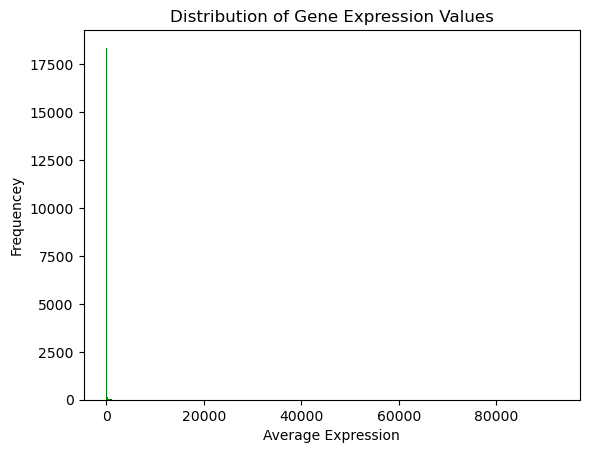

In [8]:
plt.hist(avg_expression, color = 'g', bins = 1000)
plt.title('Distribution of Gene Expression Values')
plt.xlabel('Average Expression')
plt.ylabel('Frequencey')

In [9]:
top_90 = np.percentile(avg_expression,q=90)
filtered = [i for i in avg_expression if i < top_90]

Text(0, 0.5, 'Frequencey')

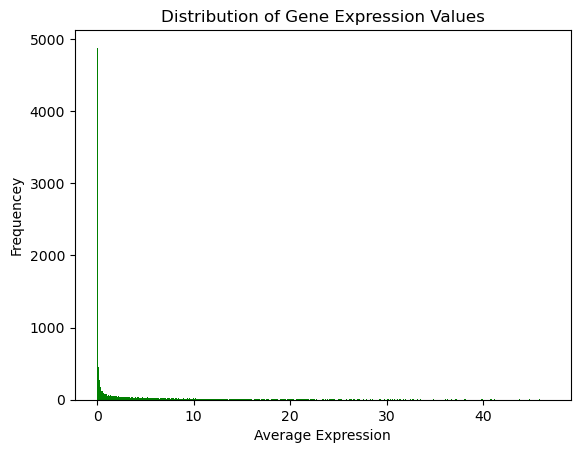

In [10]:
plt.hist(filtered, color = 'g', bins = 1000)
plt.title('Distribution of Gene Expression Values')
plt.xlabel('Average Expression')
plt.ylabel('Frequencey')

Text(0.5, 1.0, 'Average Gene Expression Box plots')

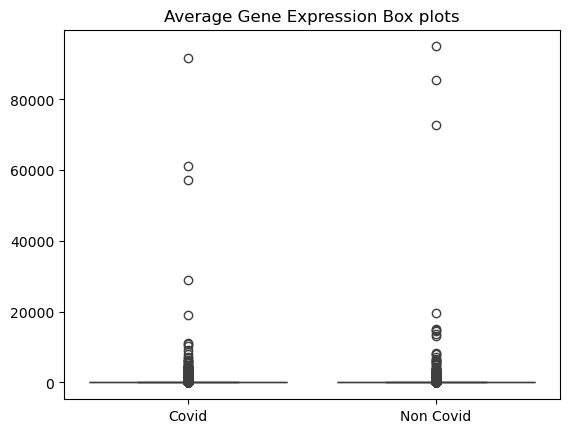

In [11]:
values = {
    'Covid': avg_expression_covid,
    'Non Covid': avg_expression_non_covid
}
sns.boxplot(values)
plt.title('Average Gene Expression Box plots')

In [12]:
change = 50
new_genes = []
for i,name in enumerate(genes):
    normal = avg_expression_non_covid[i]
    if normal == 0:
        pass
    else:
        if avg_expression_covid[i] < normal - normal*(change/100) or avg_expression_covid[i] > normal + normal*(change/100):
            new_genes.append(name)

In [13]:
len(new_genes)

6879

In [14]:
elevated_genes = []
change = 100
for i,name in enumerate(genes):
    normal = avg_expression_non_covid[i]
    normal = avg_expression_non_covid[i]
    if normal == 0:
        pass
    else:
        if avg_expression_covid[i] > normal + normal*(change/100):
            elevated_genes.append((name,avg_expression_covid[i]))

In [15]:
len(elevated_genes)
elevated_genes = sorted(elevated_genes,key= lambda x: -x[1])

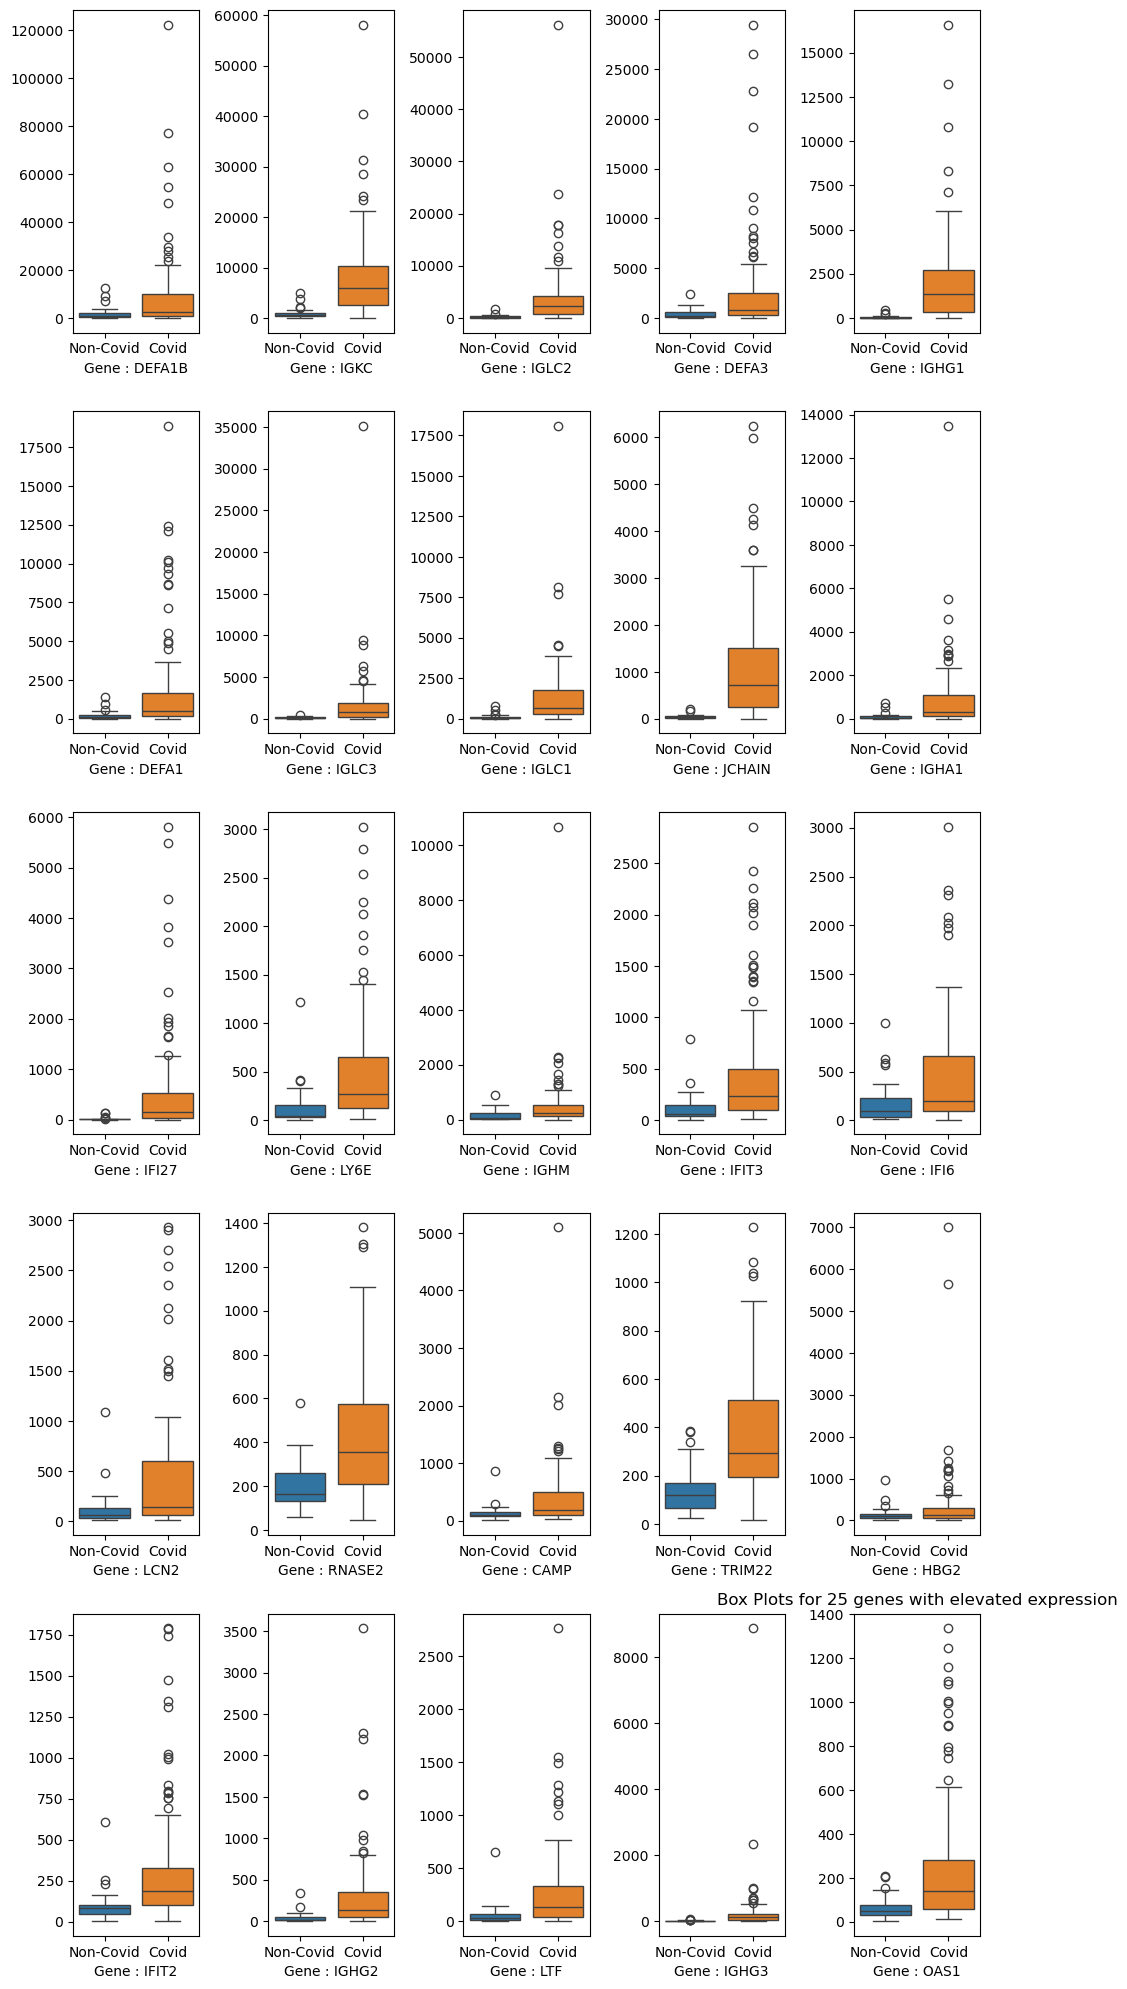

In [16]:
plt.figure(figsize=(10,20))
for i,val in enumerate(elevated_genes[:25]):
    plt.subplot(5,5,i+1)
    sns.boxplot({'Non-Covid':nc[val[0]],'Covid': cc[val[0]]})
    plt.xlabel(f'Gene : {val[0]}')
plt.title('Box Plots for 25 genes with elevated expression')
plt.tight_layout()

    

IFI27, IFI6, IFIT3, IFIT2, OAS1, LY6E, TRIM22 - antiviral defense and interferon-stimulated responses
DEFA1, DEFA1B, DEFA3, LCN2, CAMP, LTF, RNASE2 - antimicrobial defense, neutrophil granules, and inflammatory responses

In [17]:
depressed_genes = []
change = 50
for i,name in enumerate(genes):
    normal = avg_expression_non_covid[i]
    normal = avg_expression_non_covid[i]
    if normal == 0:
        pass
    else:
        if avg_expression_covid[i] < normal - normal*(change/100):
            depressed_genes.append((name,avg_expression_covid[i]))

In [18]:
len(depressed_genes)
depressed_genes = sorted(depressed_genes,key= lambda x: -x[1])

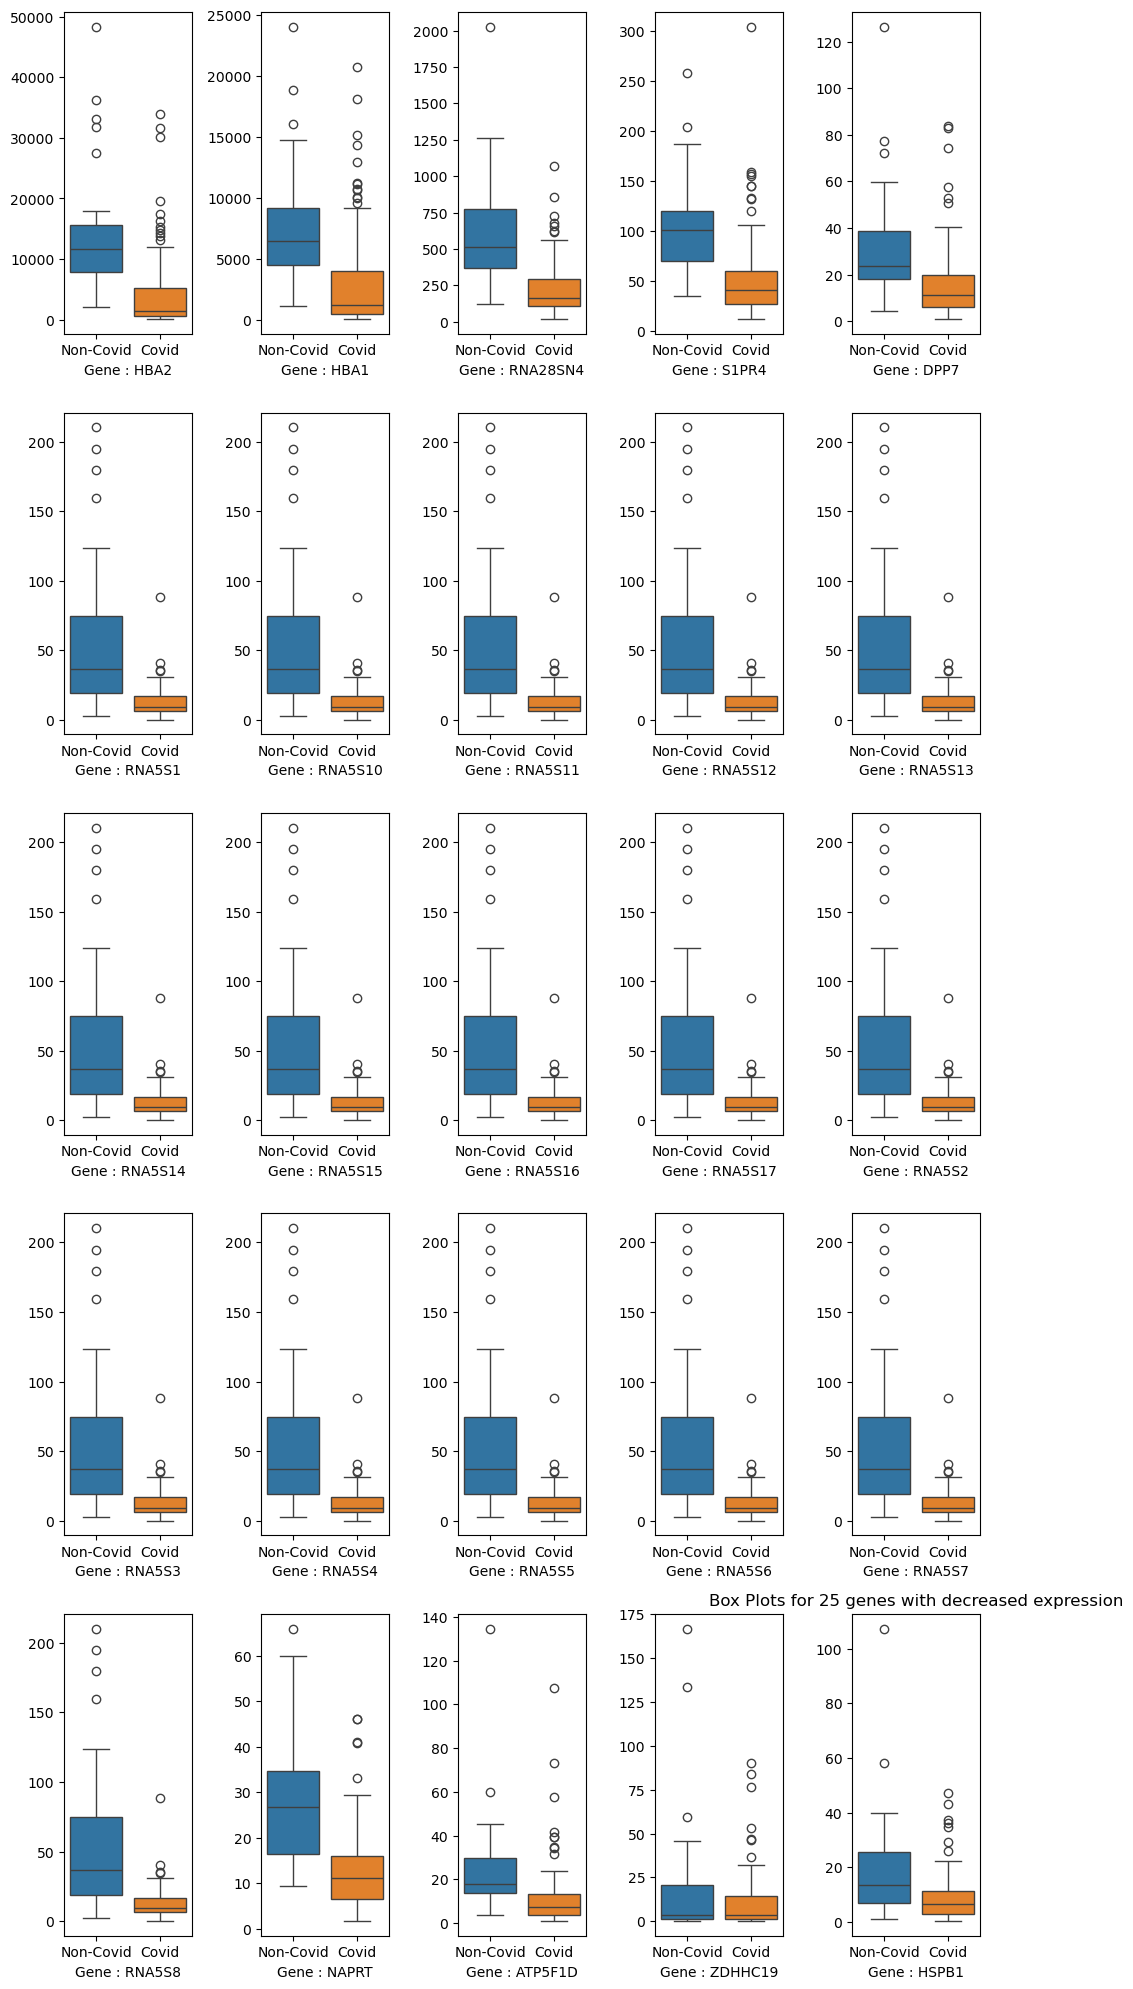

In [19]:
plt.figure(figsize=(10,20))
for i,val in enumerate(depressed_genes[:25]):
    plt.subplot(5,5,i+1)
    sns.boxplot({'Non-Covid':nc[val[0]],'Covid': cc[val[0]]})
    plt.xlabel(f'Gene : {val[0]}')
plt.title('Box Plots for 25 genes with decreased expression')
plt.tight_layout()


<Axes: xlabel='#symbol', ylabel='#symbol'>

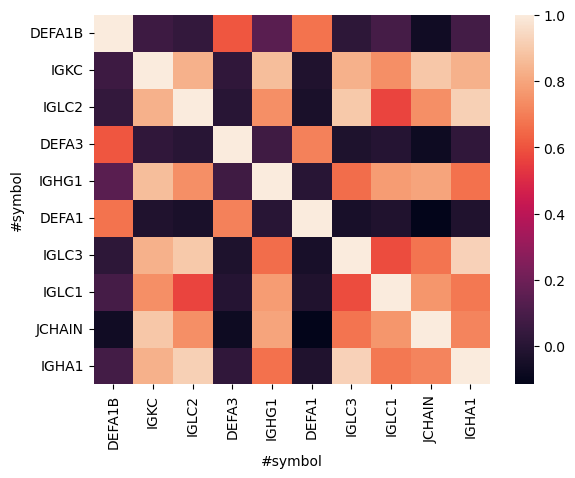

In [34]:
nd = df_t.drop(['Sample', 'Class'], axis = 1)
elev = nd[[i[0] for i in elevated_genes[:10]]]
sns.heatmap(elev.corr(method='pearson'))

In [37]:
import networkx as nx

def plot_gene_network(genes, nd, title, node_color, threshold=0.7):

    genes = list(set(genes))

    # Extract expression data and calculate correlation
    gene_data = nd[genes]
    corr_matrix = gene_data.corr(method='pearson')

    # Construct graph
    G = nx.Graph()
    G.add_nodes_from(genes)

    for i in range(len(genes)):
        for j in range(i + 1, len(genes)):

            corr = corr_matrix.iloc[i, j]

            if abs(corr) >= threshold:
                G.add_edge(
                    genes[i],
                    genes[j],
                    weight=corr
                )

    # Remove isolated nodes
    G.remove_nodes_from(list(nx.isolates(G)))

    # Identify clusters
    clusters = list(nx.connected_components(G))

    print(f"\n{title}")
    print("-" * 50)
    print(f"Total genes provided: {len(genes)}")
    print(f"Genes in network: {G.number_of_nodes()}")
    print(f"Total edges: {G.number_of_edges()}")
    print(f"Number of clusters: {len(clusters)}")

    for i, cluster in enumerate(clusters):
        print(f"\nCluster {i+1} ({len(cluster)} genes):")
        print(sorted(cluster))

    # Plot network
    plt.figure(figsize=(16, 12))

    pos = nx.spring_layout(
        G,
        seed=42,
        k=0.5
    )

    # Edge colors
    edge_colors = [
        'red' if G[u][v]['weight'] > 0 else 'blue'
        for u, v in G.edges()
    ]

    # Edge thickness
    edge_widths = [
        abs(G[u][v]['weight']) * 2
        for u, v in G.edges()
    ]

    nx.draw_networkx_nodes(
        G, pos,
        node_color=node_color,
        node_size=450,
        alpha=0.85
    )

    nx.draw_networkx_edges(
        G, pos,
        edge_color=edge_colors,
        width=edge_widths,
        alpha=0.5
    )

    nx.draw_networkx_labels(
        G, pos,
        font_size=7
    )

    plt.title(f"{title} (|r| ≥ {threshold})", fontsize=15)
    plt.axis('off')
    plt.tight_layout()
    plt.show()

    return G, clusters, corr_matrix


Elevated Gene Correlation Network
--------------------------------------------------
Total genes provided: 100
Genes in network: 92
Total edges: 700
Number of clusters: 5

Cluster 1 (56 genes):
['ADAR', 'B4GALT5', 'BTN3A1', 'CMPK2', 'CSGALNACT2', 'CYP4F3', 'DDX58', 'DDX60L', 'DHRS9', 'ELF1', 'EPSTI1', 'FAM8A1', 'GBP1', 'GBP5', 'H2BC4', 'H2BC5', 'HERC5', 'IFI27', 'IFI44', 'IFI44L', 'IFI6', 'IFIT1', 'IFIT2', 'IFIT3', 'IL18R1', 'LAP3', 'LRRK2', 'LY6E', 'MME', 'MX1', 'NT5C3A', 'OAS1', 'OAS2', 'OAS3', 'OASL', 'OLAH', 'PARP14', 'PARP9', 'PSTPIP2', 'RSAD2', 'SAMD9L', 'SAP30', 'SERPING1', 'SLC38A2', 'SMCHD1', 'STAT1', 'STAT2', 'TIMM10', 'TMEM123', 'TPST1', 'TRIM22', 'VNN1', 'VNN3', 'WLS', 'XAF1', 'ZBP1']

Cluster 2 (17 genes):
['FKBP11', 'HSP90B1', 'IGHA1', 'IGHG1', 'IGHG2', 'IGHG3', 'IGHM', 'IGKC', 'IGLC1', 'IGLC2', 'IGLC3', 'IGLL5', 'JCHAIN', 'MZB1', 'SEC11C', 'TXNDC5', 'XBP1']

Cluster 3 (13 genes):
['BPI', 'CAMP', 'CD24', 'DEFA1', 'DEFA1B', 'DEFA3', 'DEFA4', 'LCN2', 'LTF', 'MS4A3', 'OLFM4

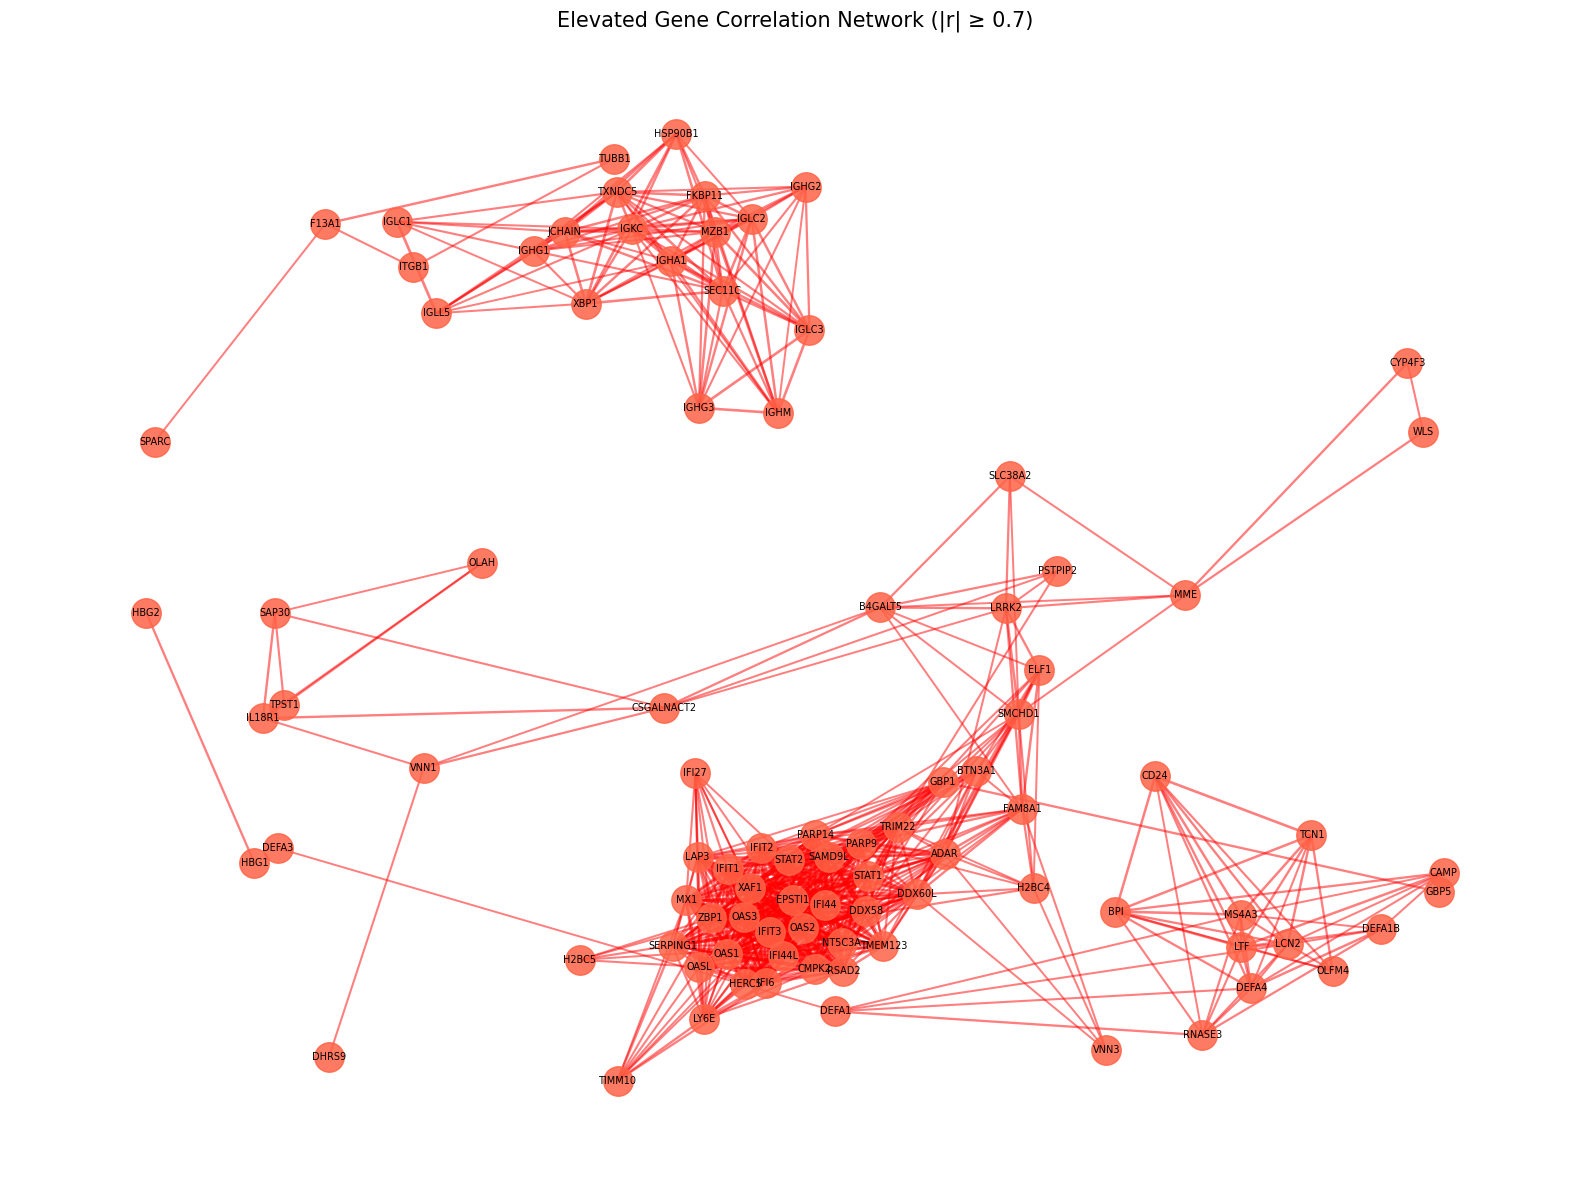

(<networkx.classes.graph.Graph at 0x18658dc6690>,
 [{'ADAR',
   'B4GALT5',
   'BTN3A1',
   'CMPK2',
   'CSGALNACT2',
   'CYP4F3',
   'DDX58',
   'DDX60L',
   'DHRS9',
   'ELF1',
   'EPSTI1',
   'FAM8A1',
   'GBP1',
   'GBP5',
   'H2BC4',
   'H2BC5',
   'HERC5',
   'IFI27',
   'IFI44',
   'IFI44L',
   'IFI6',
   'IFIT1',
   'IFIT2',
   'IFIT3',
   'IL18R1',
   'LAP3',
   'LRRK2',
   'LY6E',
   'MME',
   'MX1',
   'NT5C3A',
   'OAS1',
   'OAS2',
   'OAS3',
   'OASL',
   'OLAH',
   'PARP14',
   'PARP9',
   'PSTPIP2',
   'RSAD2',
   'SAMD9L',
   'SAP30',
   'SERPING1',
   'SLC38A2',
   'SMCHD1',
   'STAT1',
   'STAT2',
   'TIMM10',
   'TMEM123',
   'TPST1',
   'TRIM22',
   'VNN1',
   'VNN3',
   'WLS',
   'XAF1',
   'ZBP1'},
  {'FKBP11',
   'HSP90B1',
   'IGHA1',
   'IGHG1',
   'IGHG2',
   'IGHG3',
   'IGHM',
   'IGKC',
   'IGLC1',
   'IGLC2',
   'IGLC3',
   'IGLL5',
   'JCHAIN',
   'MZB1',
   'SEC11C',
   'TXNDC5',
   'XBP1'},
  {'BPI',
   'CAMP',
   'CD24',
   'DEFA1',
   'DEFA1B',
   'DE

In [40]:
elevated_gene_names = [gene[0] for gene in elevated_genes][:100]

plot_gene_network(
    elevated_gene_names,
    nd,
    "Elevated Gene Correlation Network",
    "tomato"
)


Depressed Gene Correlation Network
--------------------------------------------------
Total genes provided: 100
Genes in network: 73
Total edges: 427
Number of clusters: 4

Cluster 1 (17 genes):
['RNA5S1', 'RNA5S10', 'RNA5S11', 'RNA5S12', 'RNA5S13', 'RNA5S14', 'RNA5S15', 'RNA5S16', 'RNA5S17', 'RNA5S2', 'RNA5S3', 'RNA5S4', 'RNA5S5', 'RNA5S6', 'RNA5S7', 'RNA5S8', 'RNA5S9']

Cluster 2 (52 genes):
['ABHD16B', 'ANKS1B', 'ATP5F1D', 'BGLAP', 'BOLA2', 'C4orf48', 'CACNG6', 'CAPS', 'CRIP2', 'DNASE1L3', 'DPP7', 'ENHO', 'FAM229A', 'FNDC10', 'FXYD7', 'IGFBP6', 'IL34', 'IL4', 'JOSD2', 'LILRA4', 'LOC102724770', 'LOC114841035', 'LYNX1', 'LYPD2', 'MMP17', 'NAPRT', 'NDUFS7', 'NEURL1', 'NOXA1', 'NPDC1', 'PLD4', 'PRSS33', 'RNA28SN4', 'RNA45SN4', 'S1PR4', 'SCAND1', 'SFTPD', 'SHD', 'SLC39A4', 'SPNS3', 'SYNC', 'TAGLN', 'TMEM191B', 'TNFRSF4', 'TPGS1', 'TPPP3', 'UPK3A', 'VMO1', 'ZASP', 'ZDHHC1', 'ZNF524', 'ZNF703']

Cluster 3 (2 genes):
['HBA1', 'HBA2']

Cluster 4 (2 genes):
['CDRT4', 'CERKL']


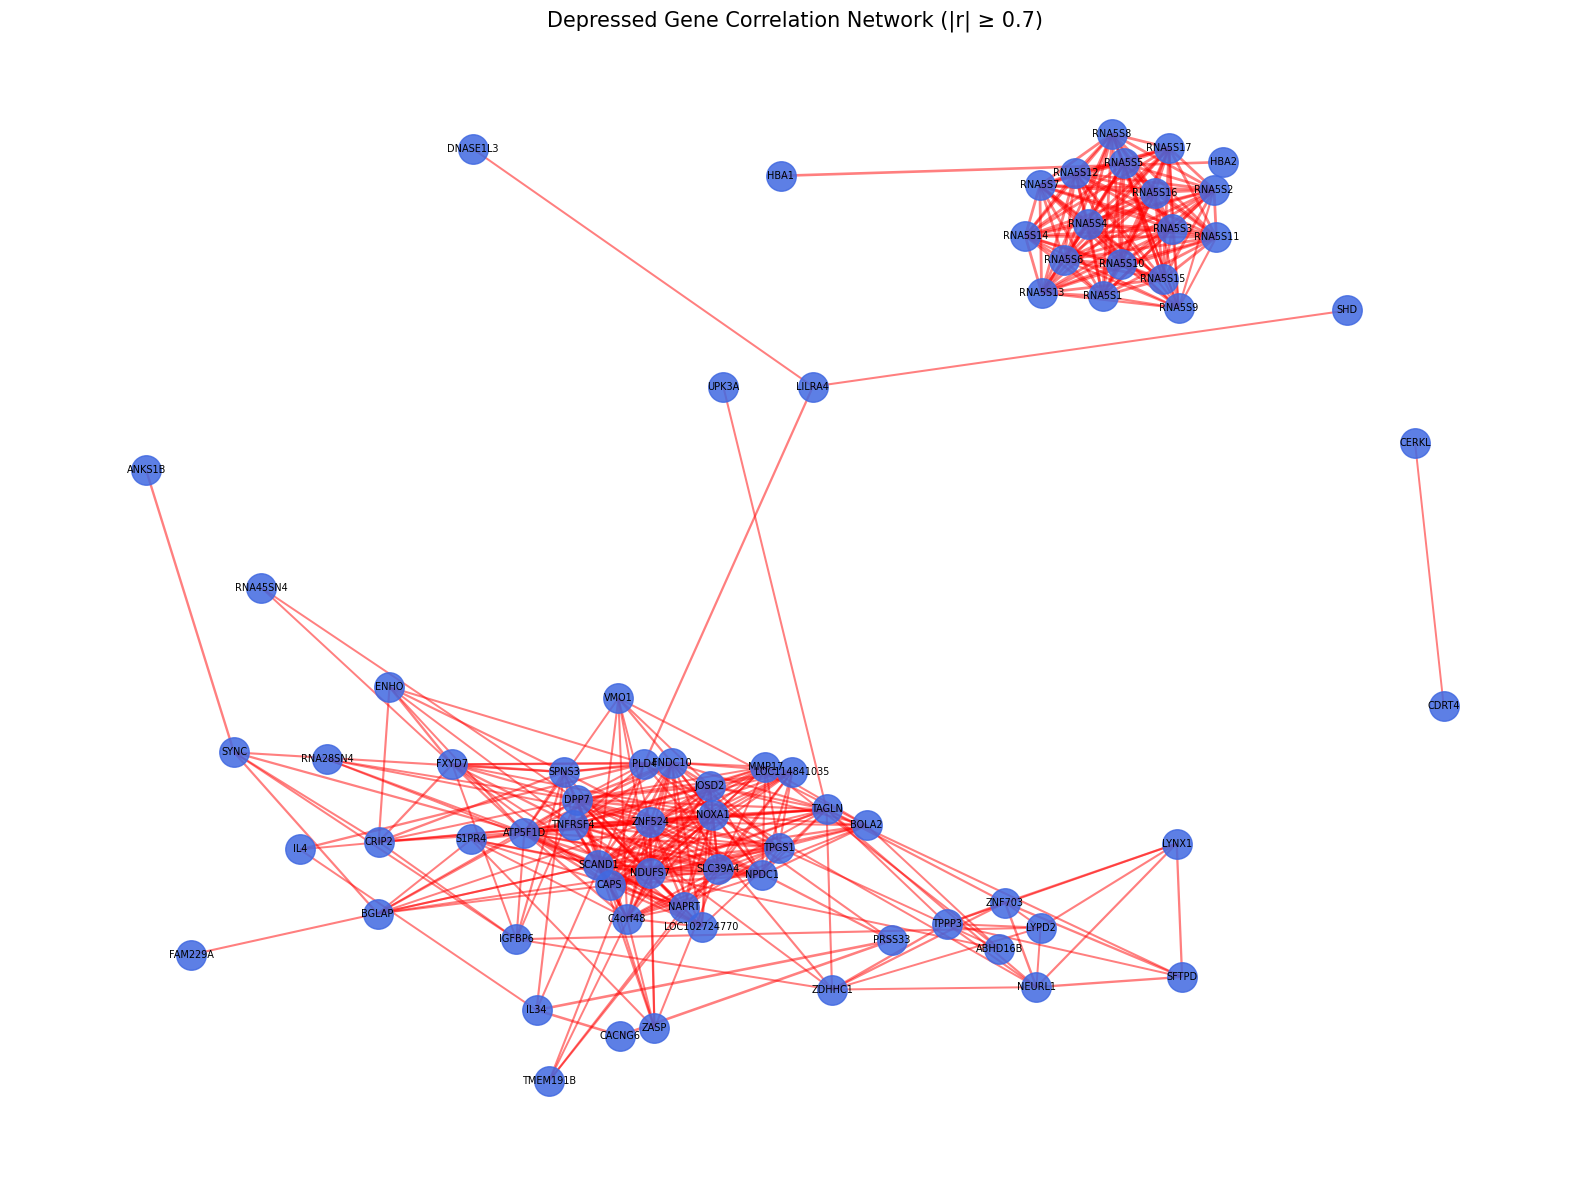

(<networkx.classes.graph.Graph at 0x18659034200>,
 [{'RNA5S1',
   'RNA5S10',
   'RNA5S11',
   'RNA5S12',
   'RNA5S13',
   'RNA5S14',
   'RNA5S15',
   'RNA5S16',
   'RNA5S17',
   'RNA5S2',
   'RNA5S3',
   'RNA5S4',
   'RNA5S5',
   'RNA5S6',
   'RNA5S7',
   'RNA5S8',
   'RNA5S9'},
  {'ABHD16B',
   'ANKS1B',
   'ATP5F1D',
   'BGLAP',
   'BOLA2',
   'C4orf48',
   'CACNG6',
   'CAPS',
   'CRIP2',
   'DNASE1L3',
   'DPP7',
   'ENHO',
   'FAM229A',
   'FNDC10',
   'FXYD7',
   'IGFBP6',
   'IL34',
   'IL4',
   'JOSD2',
   'LILRA4',
   'LOC102724770',
   'LOC114841035',
   'LYNX1',
   'LYPD2',
   'MMP17',
   'NAPRT',
   'NDUFS7',
   'NEURL1',
   'NOXA1',
   'NPDC1',
   'PLD4',
   'PRSS33',
   'RNA28SN4',
   'RNA45SN4',
   'S1PR4',
   'SCAND1',
   'SFTPD',
   'SHD',
   'SLC39A4',
   'SPNS3',
   'SYNC',
   'TAGLN',
   'TMEM191B',
   'TNFRSF4',
   'TPGS1',
   'TPPP3',
   'UPK3A',
   'VMO1',
   'ZASP',
   'ZDHHC1',
   'ZNF524',
   'ZNF703'},
  {'HBA1', 'HBA2'},
  {'CDRT4', 'CERKL'}],
 #symbol    RN

In [41]:
depressed_gene_names = [gene[0] for gene in depressed_genes][:100]

plot_gene_network(
    depressed_gene_names,
    nd,
    "Depressed Gene Correlation Network",
    "royalblue"
)


Combined Gene Correlation Network
--------------------------------------------------
Total genes provided: 200
Genes in network: 165
Total edges: 1127
Number of clusters: 9

Cluster 1 (56 genes):
['ADAR', 'B4GALT5', 'BTN3A1', 'CMPK2', 'CSGALNACT2', 'CYP4F3', 'DDX58', 'DDX60L', 'DHRS9', 'ELF1', 'EPSTI1', 'FAM8A1', 'GBP1', 'GBP5', 'H2BC4', 'H2BC5', 'HERC5', 'IFI27', 'IFI44', 'IFI44L', 'IFI6', 'IFIT1', 'IFIT2', 'IFIT3', 'IL18R1', 'LAP3', 'LRRK2', 'LY6E', 'MME', 'MX1', 'NT5C3A', 'OAS1', 'OAS2', 'OAS3', 'OASL', 'OLAH', 'PARP14', 'PARP9', 'PSTPIP2', 'RSAD2', 'SAMD9L', 'SAP30', 'SERPING1', 'SLC38A2', 'SMCHD1', 'STAT1', 'STAT2', 'TIMM10', 'TMEM123', 'TPST1', 'TRIM22', 'VNN1', 'VNN3', 'WLS', 'XAF1', 'ZBP1']

Cluster 2 (17 genes):
['RNA5S1', 'RNA5S10', 'RNA5S11', 'RNA5S12', 'RNA5S13', 'RNA5S14', 'RNA5S15', 'RNA5S16', 'RNA5S17', 'RNA5S2', 'RNA5S3', 'RNA5S4', 'RNA5S5', 'RNA5S6', 'RNA5S7', 'RNA5S8', 'RNA5S9']

Cluster 3 (52 genes):
['ABHD16B', 'ANKS1B', 'ATP5F1D', 'BGLAP', 'BOLA2', 'C4orf48', 'CAC

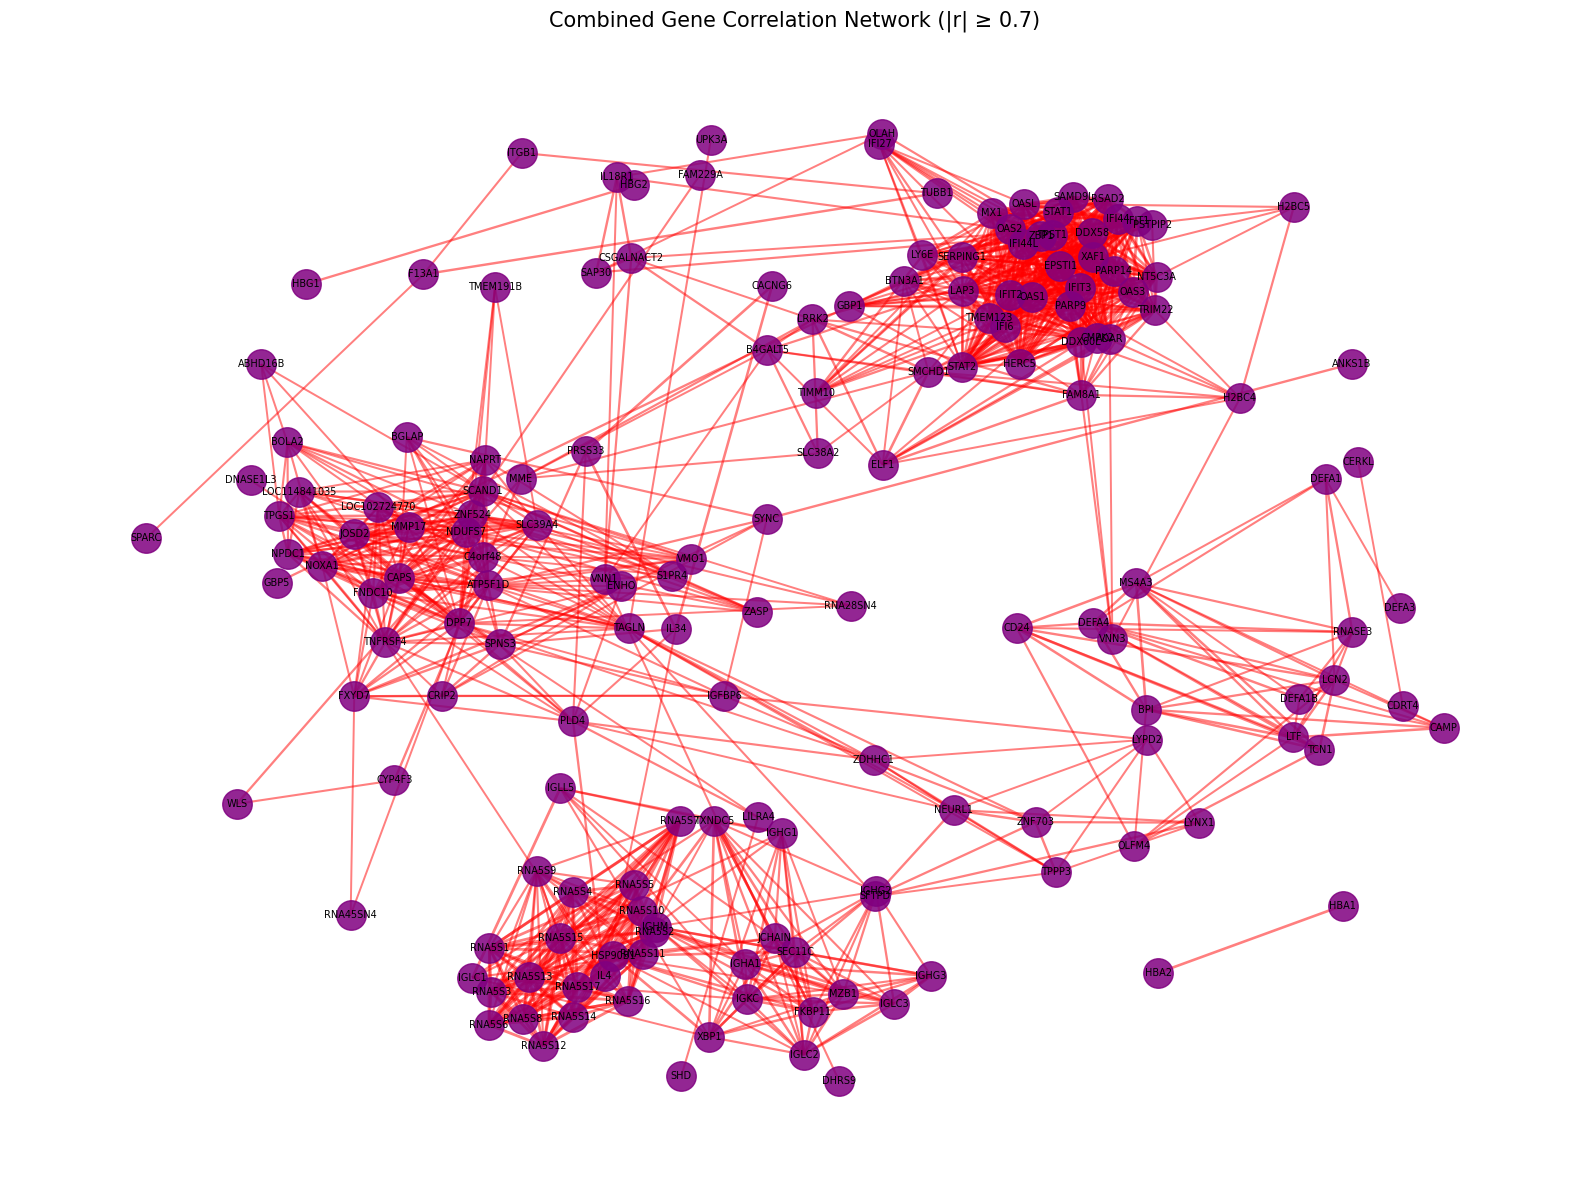

(<networkx.classes.graph.Graph at 0x18659f39880>,
 [{'ADAR',
   'B4GALT5',
   'BTN3A1',
   'CMPK2',
   'CSGALNACT2',
   'CYP4F3',
   'DDX58',
   'DDX60L',
   'DHRS9',
   'ELF1',
   'EPSTI1',
   'FAM8A1',
   'GBP1',
   'GBP5',
   'H2BC4',
   'H2BC5',
   'HERC5',
   'IFI27',
   'IFI44',
   'IFI44L',
   'IFI6',
   'IFIT1',
   'IFIT2',
   'IFIT3',
   'IL18R1',
   'LAP3',
   'LRRK2',
   'LY6E',
   'MME',
   'MX1',
   'NT5C3A',
   'OAS1',
   'OAS2',
   'OAS3',
   'OASL',
   'OLAH',
   'PARP14',
   'PARP9',
   'PSTPIP2',
   'RSAD2',
   'SAMD9L',
   'SAP30',
   'SERPING1',
   'SLC38A2',
   'SMCHD1',
   'STAT1',
   'STAT2',
   'TIMM10',
   'TMEM123',
   'TPST1',
   'TRIM22',
   'VNN1',
   'VNN3',
   'WLS',
   'XAF1',
   'ZBP1'},
  {'RNA5S1',
   'RNA5S10',
   'RNA5S11',
   'RNA5S12',
   'RNA5S13',
   'RNA5S14',
   'RNA5S15',
   'RNA5S16',
   'RNA5S17',
   'RNA5S2',
   'RNA5S3',
   'RNA5S4',
   'RNA5S5',
   'RNA5S6',
   'RNA5S7',
   'RNA5S8',
   'RNA5S9'},
  {'ABHD16B',
   'ANKS1B',
   'ATP5F1D',

In [42]:
all_gene_names = list(set(elevated_gene_names + depressed_gene_names))

plot_gene_network(
    all_gene_names,
    nd,
    "Combined Gene Correlation Network",
    "purple"
)

In [44]:
gene_names = elevated_gene_names + depressed_gene_names
PCA_data = df_t[gene_names]


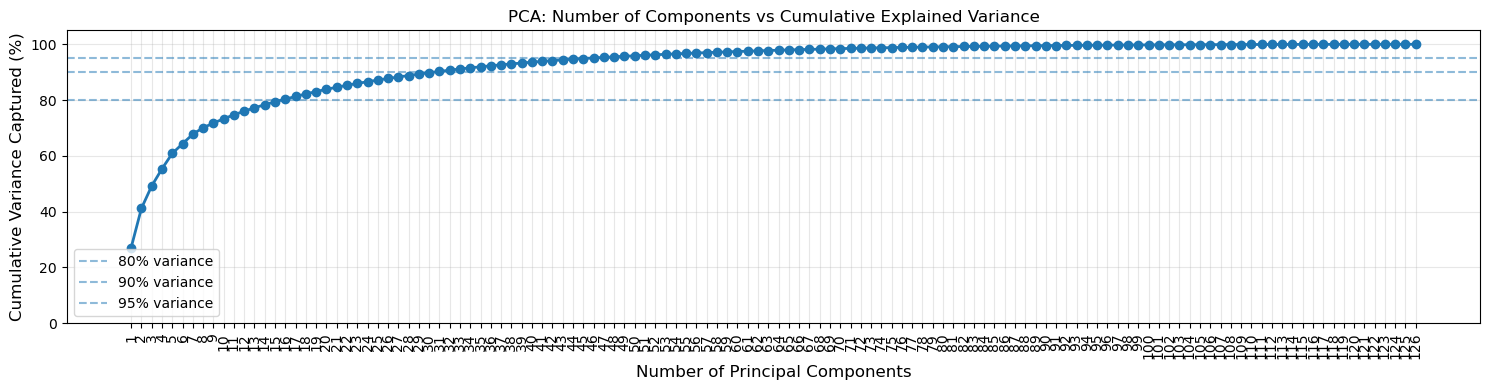

80% variance: 16 components
90% variance: 31 components
95% variance: 46 components


In [48]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
# Handle missing values
PCA_data = PCA_data.dropna(axis=0)

# Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(PCA_data)

# Perform PCA
pca = PCA()
X_pca = pca.fit_transform(X_scaled)

# Individual explained variance
explained_variance = pca.explained_variance_ratio_

# Cumulative explained variance
cumulative_variance = np.cumsum(explained_variance)

# Plot
plt.figure(figsize=(15, 4))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance * 100,
    marker='o',
    linewidth=2
)

plt.xlabel("Number of Principal Components", fontsize=12)
plt.ylabel("Cumulative Variance Captured (%)", fontsize=12)
plt.title("PCA: Number of Components vs Cumulative Explained Variance")

plt.grid(alpha=0.3)
plt.xticks(range(1, len(cumulative_variance) + 1))
plt.ylim(0, 105)

# Reference lines
for threshold in [80, 90, 95]:
    plt.axhline(y=threshold, linestyle='--', alpha=0.5,
                label=f'{threshold}% variance')

plt.legend()
plt.xticks(rotation = 90)
plt.tight_layout()
plt.show()

# Print component requirements
for threshold in [0.80, 0.90, 0.95]:
    n_components = np.argmax(cumulative_variance >= threshold) + 1
    print(f"{threshold*100:.0f}% variance: {n_components} components")

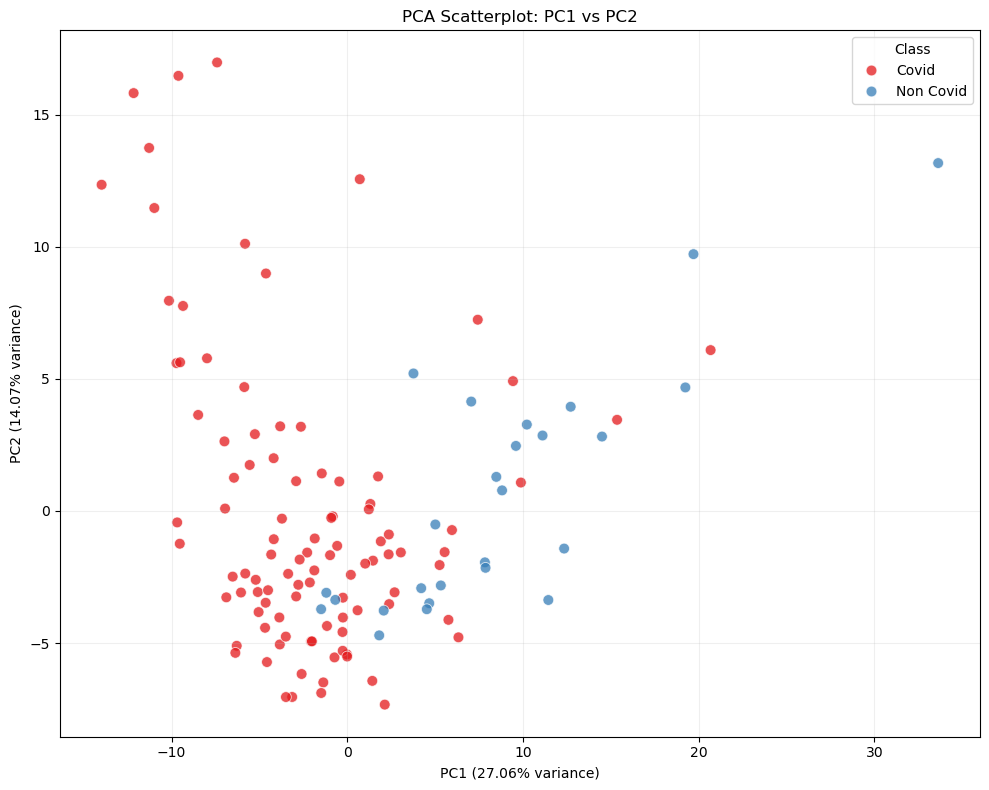

In [50]:
# Remove rows with missing values in features or Class
valid_idx = PCA_data.notna().all(axis=1) & df_t['Class'].notna()

PCA_data = PCA_data.loc[valid_idx]
classes = df_t.loc[valid_idx, 'Class']
scaler = StandardScaler()
X_scaled = scaler.fit_transform(PCA_data)

# PCA with 2 components
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Create plotting dataframe
pca_df = pd.DataFrame({
    'PC1': X_pca[:, 0],
    'PC2': X_pca[:, 1],
    'Class': classes.values
})

# Scatterplot
plt.figure(figsize=(10, 8))

sns.scatterplot(
    data=pca_df,
    x='PC1',
    y='PC2',
    hue='Class',
    palette='Set1',
    alpha=0.75,
    s=60
)

plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.2f}% variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.2f}% variance)")

plt.title("PCA Scatterplot: PC1 vs PC2")
plt.legend(title="Class")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()